# ESPRI ADC 输入的质子能量回归：左右臂独立 MLP

**功能**：读取上级 `InputRootFiles/Processed_Left.root/tree` 和 `Processed_right.root/tree`，
将模拟展宽 NaI 能量按逐棒标定反算为连续 ADC，以 `[ADC, rdcX, rdcY, NaIID]` 预测顶点质子动能 `ETrue`。

**方法**：沿用 `EspriEnergy.ipynb` 的单元格结构、CPU float64、每臂独立 80%/20% 划分，
训练集归一化、`4→64→64→64→1` Tanh MLP、Adam (1e-4)、SmoothL1Loss(beta=0.01)、
batch 256、余弦退火和固定 2000 轮；保存最后一轮完整模型，测试损失仅用于监控。

**注意事项**：使用已有 `PreProcess.C` 的清洗及物理筛选，不重新执行预处理。
`ENaI` 单位为 MeV，RDC 坐标为 mm；ADC 是标定公式的连续 Q，不取整、不加噪声，
不额外模拟电子学阈值或饱和。NaIID 直接使用已有实验统一编号 NaIBarID：
Left 1–7 对应标定 side=1、bar=ID−1；Right 8–14 对应 side=0、bar=ID−8。
预处理已经处理模拟左臂棒号反序，此处不再次反序。NaIID 作为一个数值输入归一化，不做 one-hot。
基础数据清洗沿用原 Notebook 并报告排除数；标定缺失、棒号异常、反算分母≤0、负 ADC 或回代不符时报错。
每行一个事件；SourceEntry 为预处理树行号，不能作为原始模拟 EventID。
所有新输出仅位于本文件夹的 `ADC_output/`，重新运行会覆盖同名结果。
训练及绘图由用户手动运行。图示范围不改变完整 Train/Test 统计样本。


## 1. 导入、固定随机数及输入配置
沿用原 Notebook 的 CPU float64 与超参数。实现参考 `nndl-practice/pytorch/chap4前馈神经网络/前馈神经网络-上.ipynb`
的 Sequential/Adam 模式和技能 `references/pytorch-examples/basics/regression/main.py` 的回归反向传播模式。


In [1]:
# 功能：分别训练左右臂的顶点质子动能回归模型并保存完整模型、预处理与诊断。
# 方法：4→64→64→64→1 Tanh MLP（ADC、rdcX、rdcY、NaIID），CPU/float64，独立 80/20，SmoothL1Loss、Adam+余弦退火，固定轮数。
# 统计输出：诊断图后集中打印完整 Train/Test 的五项 MeV 误差，六位小数，仅在冒号后补空格对齐数值；四输入共七幅测试诊断面板。
# 注意事项：ROOT 输入位于 InputRootFiles；只用训练集拟合归一化，测试集只监控；能量 MeV、坐标 mm；逐棒标定反算连续 ADC，异常时报错；所有输出限于 ADCToProtonEnergy。

from pathlib import Path
import json
import random
import hashlib
from IPython.display import display, Math
import numpy as np
import awkward as ak
import uproot
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

DTYPE = torch.float64
torch.set_default_dtype(DTYPE)
device = torch.device("cpu")
plt.rcParams.update({"font.size": 11, "axes.linewidth": 1.0})
print(f"PyTorch {torch.__version__}; device={device}; dtype={DTYPE}")

PROJECT_DIR = Path("/Users/yemingxin/ROOT_Exercise/MachineLearning/EspriEnergy")
WORK_DIR = PROJECT_DIR / "ADCToProtonEnergy"
CALIB_PATH = WORK_DIR / "naiCalibOutput.txt_v22"
INPUT_ROOT_DIR = PROJECT_DIR / "InputRootFiles"
INPUT_FILES = {
    "Left": INPUT_ROOT_DIR / "Processed_Left.root",
    "Right": INPUT_ROOT_DIR / "Processed_right.root",
}
TREE_NAME = "tree"
FEATURE_NAMES = ["ADC", "rdcX", "rdcY", "NaIID"]
FEATURE_UNITS = ["channel", "mm", "mm", "1"]
SOURCE_BRANCHES = ["ENaI", "RDCX", "RDCY", "NaIBarID"]
ARM_CALIB = {"Left": {"side": 1, "id_min": 1}, "Right": {"side": 0, "id_min": 8}}
TARGET_NAME = "ETrue"
INVALID_VALUE = -999.0
ARM_SEEDS = {"Left": 42, "Right": 43}
TRAIN_FRACTION = 0.80
RESIDUAL_HIST_MIN_MEV = -10.0
RESIDUAL_HIST_MAX_MEV = 10.0
RESIDUAL_HIST_BIN_WIDTH_MEV = 0.2

OUTPUT_DIR = WORK_DIR / "ADC_output"
OUTPUT_DIR.mkdir(parents=False, exist_ok=True)
print("输出目录：", OUTPUT_DIR)
print("两个预测 Notebook 默认读取此固定模型目录。")

display(Math(r"E_{\mathrm{NaI}}=\frac{A Q}{1+B Q}+C,\qquad Q=\frac{E_{\mathrm{NaI}}-C}{A-B(E_{\mathrm{NaI}}-C)}"))
display(Math(r"\widehat{E}_{\mathrm{True}}=f_\theta(Q,\mathrm{rdcX},\mathrm{rdcY},\mathrm{NaIID})"))


PyTorch 2.5.1; device=cpu; dtype=torch.float64
输出目录： /Users/yemingxin/ROOT_Exercise/MachineLearning/EspriEnergy/ADCToProtonEnergy/ADC_output
两个预测 Notebook 默认读取此固定模型目录。


<IPython.core.display.Math object>

<IPython.core.display.Math object>

## 2. 读取 ROOT、逐棒反算 ADC 并检查事件对齐
读取 ENaI、RDCX、RDCY、NaIBarID 和 ETrue；保持同一 ROOT entry 的对应关系。
基础清洗沿用原版：排除非有限能量/坐标、ENaI≤0、能量/坐标为 -999 或标签非有限/≤0，报告计数。
NaIBarID 必须为对应臂的合法整数，异常停止。对通过基础清洗的每行，按其棒号查找 A、B、C。
反算要求 A>0、E−C≥0、A−B(E−C)>0、Q 有限且非负、1+BQ>0，并回代检查。
反算异常不静默删事件、不裁剪能量、不截断 ADC；报出 SourceEntry 并停止。


In [2]:
def read_features(path, tree_name, feature_names, target_name="ETrue"):
    """读取标量预处理树；保留全部行，标签可以不存在。"""
    path = Path(path).expanduser().resolve()
    if not path.is_file():
        raise FileNotFoundError(f"ROOT 文件不存在：{path}")
    with uproot.open(path) as root_file:
        tree = root_file[tree_name]
        missing = [name for name in feature_names if name not in tree.keys()]
        if missing:
            raise ValueError(f"{path.name}/{tree_name} 缺少输入分支：{missing}")
        has_target = target_name in tree.keys()
        names = list(feature_names) + ([target_name] if has_target else [])
        arrays = tree.arrays(names, library="ak", how=dict)
        columns = [np.asarray(ak.to_numpy(arrays[name]), dtype=np.float64) for name in names]
        if any(column.ndim != 1 for column in columns):
            raise ValueError("需要每个事件一行的标量分支，不接受未预处理的多命中数组。")
        if len({len(column) for column in columns}) != 1:
            raise ValueError("输入与标签的行数不一致。")
        X = np.column_stack(columns[:len(feature_names)]).astype(np.float64)
        y = columns[-1].reshape(-1, 1) if has_target else None
    return X, y


def valid_features(X):
    # 不新增角度或坐标接受度门；预处理已经负责物理筛选。
    finite = np.isfinite(X).all(axis=1)
    return finite & (X[:, 0] > 0.0) & (X != INVALID_VALUE).all(axis=1)

def load_calibration(path):
    """严格读取 side, bar, A, B, C 共 14 行，保留原文件内容用于追溯。"""
    raw = path.read_bytes()
    table = np.loadtxt(raw.decode("utf-8").splitlines(), dtype=np.float64, ndmin=2)
    if table.shape != (14, 5) or not np.isfinite(table).all():
        raise ValueError("标定表应为 14×5 个有限数值：side, bar, A, B, C。")
    mapping = {}
    for side, bar, a, b, c in table:
        if side not in (0, 1) or bar != np.floor(bar) or not 0 <= bar <= 6 or a <= 0:
            raise ValueError(f"标定表含非法行：{side, bar, a, b, c}")
        key = (int(side), int(bar))
        if key in mapping:
            raise ValueError(f"重复标定键：{key}")
        mapping[key] = np.array([a, b, c], dtype=np.float64)
    if set(mapping) != {(s, b) for s in (0, 1) for b in range(7)}:
        raise ValueError("标定表缺失 side/bar。")
    return mapping, table, raw


def energy_to_adc(energy, coefficients, source_rows, arm):
    """连续反演并验证原公式的物理解；不取整、裁剪或添加噪声。"""
    a, b, c = coefficients.T
    delta = energy - c
    denominator = a - b * delta
    ok = np.isfinite(delta) & (delta >= 0.0) & np.isfinite(denominator) & (denominator > 0.0)
    if not ok.all():
        bad = np.flatnonzero(~ok)[:10]
        raise ValueError(f"{arm} ADC 反算无物理解；SourceEntry={source_rows[bad].tolist()}, "
                         f"ENaI={energy[bad].tolist()}, denominator={denominator[bad].tolist()}")
    with np.errstate(over="ignore", invalid="ignore", divide="ignore"):
        adc = delta / denominator
        forward_denominator = 1.0 + b * adc
        recovered = a * adc / forward_denominator + c
    ok = (np.isfinite(adc) & (adc >= 0.0) & np.isfinite(forward_denominator)
          & (forward_denominator > 0.0) & np.isfinite(recovered)
          & np.isclose(recovered, energy, rtol=1e-10, atol=1e-10))
    if not ok.all():
        raise ValueError(f"{arm} ADC/回代异常；SourceEntry={source_rows[~ok][:10].tolist()}")
    return adc


calibration, calib_table, calib_raw = load_calibration(CALIB_PATH)
calib_sha256 = hashlib.sha256(calib_raw).hexdigest()
print("标定表：", CALIB_PATH, "SHA256:", calib_sha256)
datasets = {}
for arm, path in INPUT_FILES.items():
    raw_X, y_all = read_features(path, TREE_NAME, SOURCE_BRANCHES, TARGET_NAME)
    if y_all is None:
        raise ValueError(f"{arm} 训练文件必须包含 {TARGET_NAME}。")
    ids = raw_X[:, 3]
    rule = ARM_CALIB[arm]
    id_ok = (np.isfinite(ids) & (ids == np.floor(ids))
             & (ids >= rule["id_min"]) & (ids <= rule["id_min"] + 6))
    if not id_ok.all():
        raise ValueError(f"{arm} NaIBarID 非法；SourceEntry={np.flatnonzero(~id_ok)[:10].tolist()}")
    input_ok = valid_features(raw_X[:, :3])
    target_ok = np.isfinite(y_all[:, 0]) & (y_all[:, 0] > 0.0)
    keep = input_ok & target_ok
    source_rows = np.flatnonzero(keep).astype(np.int64)
    selected = raw_X[keep]
    y = y_all[keep]
    if len(selected) < 5:
        raise ValueError(f"{arm} 有效事件数不足以划分训练/测试集。")
    selected_ids = selected[:, 3].astype(np.int64)
    coefficients = np.stack([calibration[(rule["side"], int(i - rule["id_min"]))]
                             for i in selected_ids])
    adc = energy_to_adc(selected[:, 0], coefficients, source_rows, arm)
    X = np.column_stack((adc, selected[:, 1:3], selected_ids)).astype(np.float64)
    if X.shape != (len(y), 4) or not np.isfinite(X).all():
        raise ValueError(f"{arm} 特征长度、形状或有限值异常。")
    datasets[arm] = {
        "X": X, "y": y, "source_rows": source_rows, "input_path": path.resolve(),
        "energy_nai": selected[:, 0].copy(),
        "input_sha256": hashlib.sha256(path.read_bytes()).hexdigest(),
        "original_entries": len(raw_X), "rejected_entries": int((~keep).sum()),
    }
    print(f"{arm}: 原始 {len(raw_X)}，输入无效 {(~input_ok).sum()}，标签无效 {(~target_ok).sum()}，"
          f"合计排除 {(~keep).sum()}，保留 {len(X)}")
    print("  feature minima:", dict(zip(FEATURE_NAMES, X.min(axis=0))))
    print("  feature maxima:", dict(zip(FEATURE_NAMES, X.max(axis=0))))
    print("  各棒事件数:", dict(zip(*np.unique(selected_ids, return_counts=True))))


标定表： /Users/yemingxin/ROOT_Exercise/MachineLearning/EspriEnergy/ADCToProtonEnergy/naiCalibOutput.txt_v22 SHA256: e8a0d6c5c0441b800ef5b3ce49a25f577bdafd32006c97bd6fa194f87a1aa99b
Left: 原始 24006，输入无效 0，标签无效 0，合计排除 0，保留 24006
  feature minima: {'ADC': np.float64(6.632349409261913), 'rdcX': np.float64(112.06673818573219), 'rdcY': np.float64(18.522068663701816), 'NaIID': np.float64(1.0)}
  feature maxima: {'ADC': np.float64(4959.014441461032), 'rdcX': np.float64(399.3273479131202), 'rdcY': np.float64(427.92354384297494), 'NaIID': np.float64(7.0)}
  各棒事件数: {np.int64(1): np.int64(3630), np.int64(2): np.int64(3116), np.int64(3): np.int64(3898), np.int64(4): np.int64(3162), np.int64(5): np.int64(3685), np.int64(6): np.int64(3184), np.int64(7): np.int64(3331)}
Right: 原始 24149，输入无效 0，标签无效 0，合计排除 0，保留 24149
  feature minima: {'ADC': np.float64(3.5126469550565806), 'rdcX': np.float64(48.45831757412378), 'rdcY': np.float64(24.51877856102081), 'NaIID': np.float64(8.0)}
  feature maxima: {'ADC': np.fl

## 3. 划分与训练集归一化
Left 使用 seed 42，Right 使用 seed 43，分别固定随机打乱后划分 80%/20%。
每臂的均值、标准差只从自己的训练集计算；保持已有划分算法，以便比较损失函数的影响。
常量输入列按训练集极差识别，均值取实际常量、缩放量设为 1。

In [3]:
splits = {}
for arm, data in datasets.items():
    rng = np.random.default_rng(ARM_SEEDS[arm])
    order = rng.permutation(len(data["X"]))
    n_train = int(TRAIN_FRACTION * len(order))
    train_idx, test_idx = order[:n_train], order[n_train:]
    X_train, X_test = data["X"][train_idx], data["X"][test_idx]
    y_train, y_test = data["y"][train_idx], data["y"][test_idx]

    x_mean = X_train.mean(axis=0)
    x_std_raw = X_train.std(axis=0)
    constant_features = np.ptp(X_train, axis=0) == 0.0
    x_mean[constant_features] = X_train[0, constant_features]
    x_std = np.where(constant_features | (x_std_raw == 0.0), 1.0, x_std_raw)
    y_mean = y_train.mean(axis=0)
    y_std = y_train.std(axis=0)
    if np.ptp(y_train) == 0.0:
        raise ValueError(f"{arm} 训练标签是常量，无法学习能损映射。")
    y_std = np.where(y_std == 0.0, 1.0, y_std)

    X_train_n = (X_train - x_mean) / x_std
    X_test_n = (X_test - x_mean) / x_std
    y_train_n = (y_train - y_mean) / y_std
    y_test_n = (y_test - y_mean) / y_std
    splits[arm] = {
        "train_idx": train_idx, "test_idx": test_idx,
        "X_train": X_train, "X_test": X_test, "y_train": y_train, "y_test": y_test,
        "X_train_n": X_train_n, "X_test_n": X_test_n,
        "y_train_n": y_train_n, "y_test_n": y_test_n,
        "x_mean": x_mean, "x_std": x_std, "y_mean": y_mean, "y_std": y_std,
        "constant_features": constant_features,
    }
    print(f"{arm}: train={len(train_idx)}, test/monitor={len(test_idx)}")
    print("  constant features:", [name for name, flag in zip(FEATURE_NAMES, constant_features) if flag])
    print("  training target mean/std (MeV):", y_mean, y_std)

display(Math(r"x'=\frac{x-\mu_{x,\mathrm{train}}}{s_{x,\mathrm{train}}},\qquad y'=\frac{y-\mu_{y,\mathrm{train}}}{s_{y,\mathrm{train}}}"))


Left: train=19204, test/monitor=4802
  constant features: []
  training target mean/std (MeV): [94.2230315] [36.67308054]
Right: train=19319, test/monitor=4830
  constant features: []
  training target mean/std (MeV): [93.9900532] [36.51625419]


<IPython.core.display.Math object>

## 4. 张量与 MLP
显式定义 `4→64→64→64→1`，三个隐藏层使用 Tanh，输出层为线性层。
左右臂使用相同结构、各自独立的模型参数和训练集归一化。所有张量与模型均使用 CPU float64。

In [4]:
def to_tensor(array):
    return torch.from_numpy(np.ascontiguousarray(array, dtype=np.float64)).to(
        device=device, dtype=DTYPE
    )


for arm in ("Left", "Right"):
    split = splits[arm]
    X_train_n, y_train_n = split["X_train_n"], split["y_train_n"]
    X_test_n, y_test_n = split["X_test_n"], split["y_test_n"]
    X_train_t, y_train_t = to_tensor(X_train_n), to_tensor(y_train_n)
    X_test_t, y_test_t = to_tensor(X_test_n), to_tensor(y_test_n)
    split.update({
        "X_train_t": X_train_t, "y_train_t": y_train_t,
        "X_test_t": X_test_t, "y_test_t": y_test_t,
    })


# 显式定义 4 -> 64 -> 64 -> 64 -> 1，三个隐藏层使用 Tanh。
def build_model():
    return nn.Sequential(
        nn.Linear(4, 64), nn.Tanh(),
        nn.Linear(64, 64), nn.Tanh(),
        nn.Linear(64, 64), nn.Tanh(),
        nn.Linear(64, 1),
    )


print(build_model())


Sequential(
  (0): Linear(in_features=4, out_features=64, bias=True)
  (1): Tanh()
  (2): Linear(in_features=64, out_features=64, bias=True)
  (3): Tanh()
  (4): Linear(in_features=64, out_features=64, bias=True)
  (5): Tanh()
  (6): Linear(in_features=64, out_features=1, bias=True)
)


## 5. 固定轮数训练与完整集合损失监控
训练参数和循环在本单元格直接给出。重新执行时，每臂从各自固定种子初始化全新模型、
优化器、余弦学习率调度器和 DataLoader 随机生成器。
使用 `nn.SmoothL1Loss(beta=0.01)`；beta 作用于标准化标签残差，不是 0.01 MeV。
固定训练 2000 轮，不早停、不按测试损失选权重。
每轮更新结束后，在同一模型状态下用 eval()/no_grad() 重算完整训练集和测试集损失。

In [5]:
display(Math(r"L_\beta(r')=\begin{cases}(r')^2/(2\beta),&|r'|<\beta\\|r'|-\beta/2,&|r'|\ge\beta\end{cases},\quad r'=\hat y'-y',\quad\beta=0.01"))
# 训练参数在本单元格显式定义，便于直接修改。
LEARNING_RATE = 1e-4
MINIMUM_LEARNING_RATE = 1e-6
epoch_count = 2000
COSINE_EPOCHS = epoch_count
BATCH_SIZE = 256
WEIGHT_DECAY = 0.0
SMOOTH_L1_BETA = 0.01  # 作用于标准化标签残差，不是 0.01 MeV。beta 越大，采用二次惩罚的区间越宽
LOG_EVERY = 100

models, histories = {}, {}
for arm in ("Left", "Right"):
    split = splits[arm]
    X_train_t, y_train_t = split["X_train_t"], split["y_train_t"]
    X_test_t, y_test_t = split["X_test_t"], split["y_test_t"]
    seed = ARM_SEEDS[arm]
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    model = build_model().to(device=device, dtype=DTYPE)
    criterion = nn.SmoothL1Loss(beta=SMOOTH_L1_BETA)
    optimizer = torch.optim.Adam(
        model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=COSINE_EPOCHS, eta_min=MINIMUM_LEARNING_RATE
    )
    loader_generator = torch.Generator(device="cpu").manual_seed(seed)
    train_loader = DataLoader(
        TensorDataset(X_train_t, y_train_t),
        batch_size=BATCH_SIZE, shuffle=True, generator=loader_generator,
        num_workers=0, drop_last=False,
    )

    train_loss_history, test_loss_history, learning_rate_history = [], [], []
    print(f"\nTraining {arm}: CPU float64, SmoothL1Loss(beta={SMOOTH_L1_BETA})")
    print(model)
    for epoch in range(1, epoch_count + 1):
        learning_rate_history.append(float(optimizer.param_groups[0]["lr"]))
        model.train()
        for xb, yb in train_loader:
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(xb), yb)
            if not torch.isfinite(loss).item():
                raise RuntimeError(f"{arm} epoch {epoch} 训练损失出现 NaN/Inf。")
            loss.backward()
            optimizer.step()

        model.eval()
        with torch.no_grad():
            train_loss = criterion(model(X_train_t), y_train_t).item()
            test_loss = criterion(model(X_test_t), y_test_t).item()
        if not np.isfinite(train_loss) or not np.isfinite(test_loss):
            raise RuntimeError(f"{arm} epoch {epoch} 完整集合损失出现 NaN/Inf。")
        train_loss_history.append(train_loss)
        test_loss_history.append(test_loss)
        scheduler.step()
        if epoch == 1 or epoch % LOG_EVERY == 0 or epoch == epoch_count:
            print(f"{arm} epoch {epoch:4d}/{epoch_count}: train={train_loss:.6g}, "
                  f"test/monitor={test_loss:.6g}, lr={learning_rate_history[-1]:.4g}")

    model.eval()
    models[arm] = model
    histories[arm] = {
        "train_loss_history": train_loss_history,
        "test_loss_history": test_loss_history,
        "learning_rate": learning_rate_history,
    }
    print(f"Finished {arm}: {epoch_count} epochs; using final model weights.")


<IPython.core.display.Math object>


Training Left: CPU float64, SmoothL1Loss(beta=0.01)
Sequential(
  (0): Linear(in_features=4, out_features=64, bias=True)
  (1): Tanh()
  (2): Linear(in_features=64, out_features=64, bias=True)
  (3): Tanh()
  (4): Linear(in_features=64, out_features=64, bias=True)
  (5): Tanh()
  (6): Linear(in_features=64, out_features=1, bias=True)
)
Left epoch    1/2000: train=0.496668, test/monitor=0.49723, lr=0.0001
Left epoch  100/2000: train=0.096581, test/monitor=0.0960923, lr=9.94e-05
Left epoch  200/2000: train=0.0407931, test/monitor=0.0405977, lr=9.76e-05
Left epoch  300/2000: train=0.0197656, test/monitor=0.0204225, lr=9.464e-05
Left epoch  400/2000: train=0.0199031, test/monitor=0.0204927, lr=9.059e-05
Left epoch  500/2000: train=0.0166629, test/monitor=0.0175614, lr=8.556e-05
Left epoch  600/2000: train=0.0182418, test/monitor=0.0192547, lr=7.966e-05
Left epoch  700/2000: train=0.0166398, test/monitor=0.0173969, lr=7.304e-05
Left epoch  800/2000: train=0.014144, test/monitor=0.0150974, 

## 6. 单独绘制损失曲线
两条曲线都是每轮结束后同一模型状态下的完整集合 SmoothL1 loss，纵轴采用对数。
左右臂独立显示；20% 数据仅用于监控。

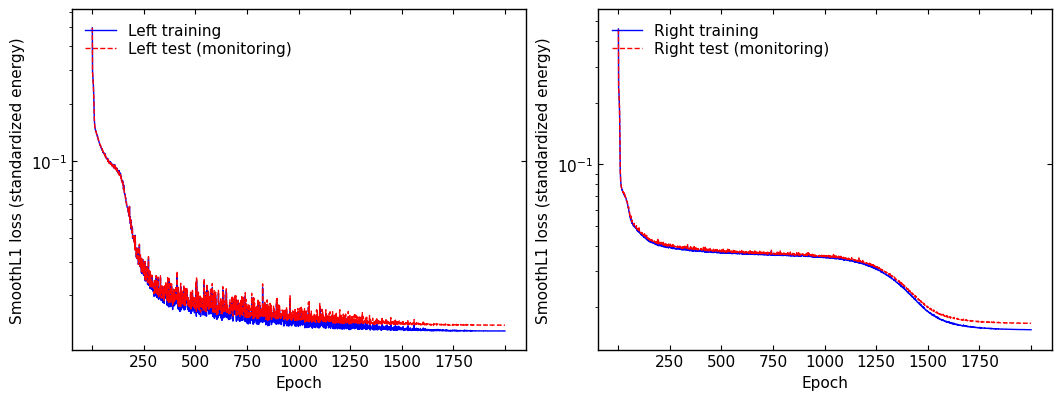

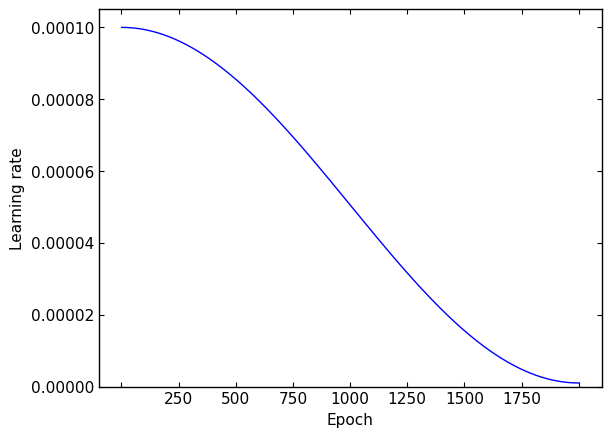

In [6]:
def finish_figure(fig, axes, path):
    """统一绘图区比例，隐藏横轴首尾可见刻度文字，并紧凑导出。"""
    axes = np.asarray(axes, dtype=object).reshape(-1)
    for ax in axes:
        ax.set_box_aspect(3.0 / 4.0)
        ax.grid(False)
        ax.tick_params(direction="in", top=True, right=True)
    fig.canvas.draw()
    for ax in axes:
        low, high = sorted(ax.get_xlim())
        labels = [tick.label1 for tick in ax.xaxis.get_major_ticks()
                  if low <= tick.get_loc() <= high and tick.label1.get_visible()]
        if len(labels) > 1:
            labels[0].set_visible(False)
            labels[-1].set_visible(False)
    fig.savefig(path, bbox_inches="tight", pad_inches=0.06)
    fig.savefig(path.with_suffix(".png"), dpi=180, bbox_inches="tight", pad_inches=0.06)
    plt.show()
    plt.close(fig)

epochs = np.arange(1, epoch_count + 1)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2), layout="constrained")
for ax, arm in zip(axes, ("Left", "Right")):
    ax.plot(epochs, histories[arm]["train_loss_history"], color="blue", linewidth=1, label=f"{arm} training")
    ax.plot(epochs, histories[arm]["test_loss_history"], color="red", linestyle="--", linewidth=1, label=f"{arm} test (monitoring)")
    ax.set(yscale="log", xlabel="Epoch", ylabel="SmoothL1 loss (standardized energy)")
    loss_values = np.concatenate((histories[arm]["train_loss_history"], histories[arm]["test_loss_history"]))
    positive_losses = loss_values[loss_values > 0.0]
    if len(positive_losses):
        ax.set_ylim(0.8 * positive_losses.min(), 1.25 * positive_losses.max())
    ax.legend(frameon=False, loc="upper left", labelspacing=0.2)
finish_figure(fig, axes, OUTPUT_DIR / "LossCurves.pdf")

fig, ax = plt.subplots(figsize=(6, 4.5), layout="constrained")
# 两臂调度参数一致，显示每轮优化器实际使用的共同学习率。
ax.plot(epochs, histories["Left"]["learning_rate"], color="blue", linewidth=1)
ax.set(xlabel="Epoch", ylabel="Learning rate")
ax.set_ylim(0.0, 1.05 * LEARNING_RATE)
finish_figure(fig, [ax], OUTPUT_DIR / "LearningRate.pdf")


## 7. 固定轮数后的预测和残差（MeV）
残差定义为预测减真值；反归一化后，在诊断图输出完成后集中打印左右臂完整 Train/Test 的
MAE、Bias、RMSE、RMS_68、W_68，保留六位小数及 MeV 单位；仅在冒号后补空格对齐数值。
RMS_68 使用残差 Q16–Q84 区间内事件的均方根；JSON 另保留 MSE、R²、残差标准差及分位数。
评价 MSE 与训练 SmoothL1 是不同的量。
柱状图显示 [-10,10] MeV，bin 宽0.2 MeV；统计指标仍使用全部有效事件。
SourceEntry 是预处理树零起始行号。

Left internal test: residual histogram below range=14, above range=0; metrics use all 4802 events


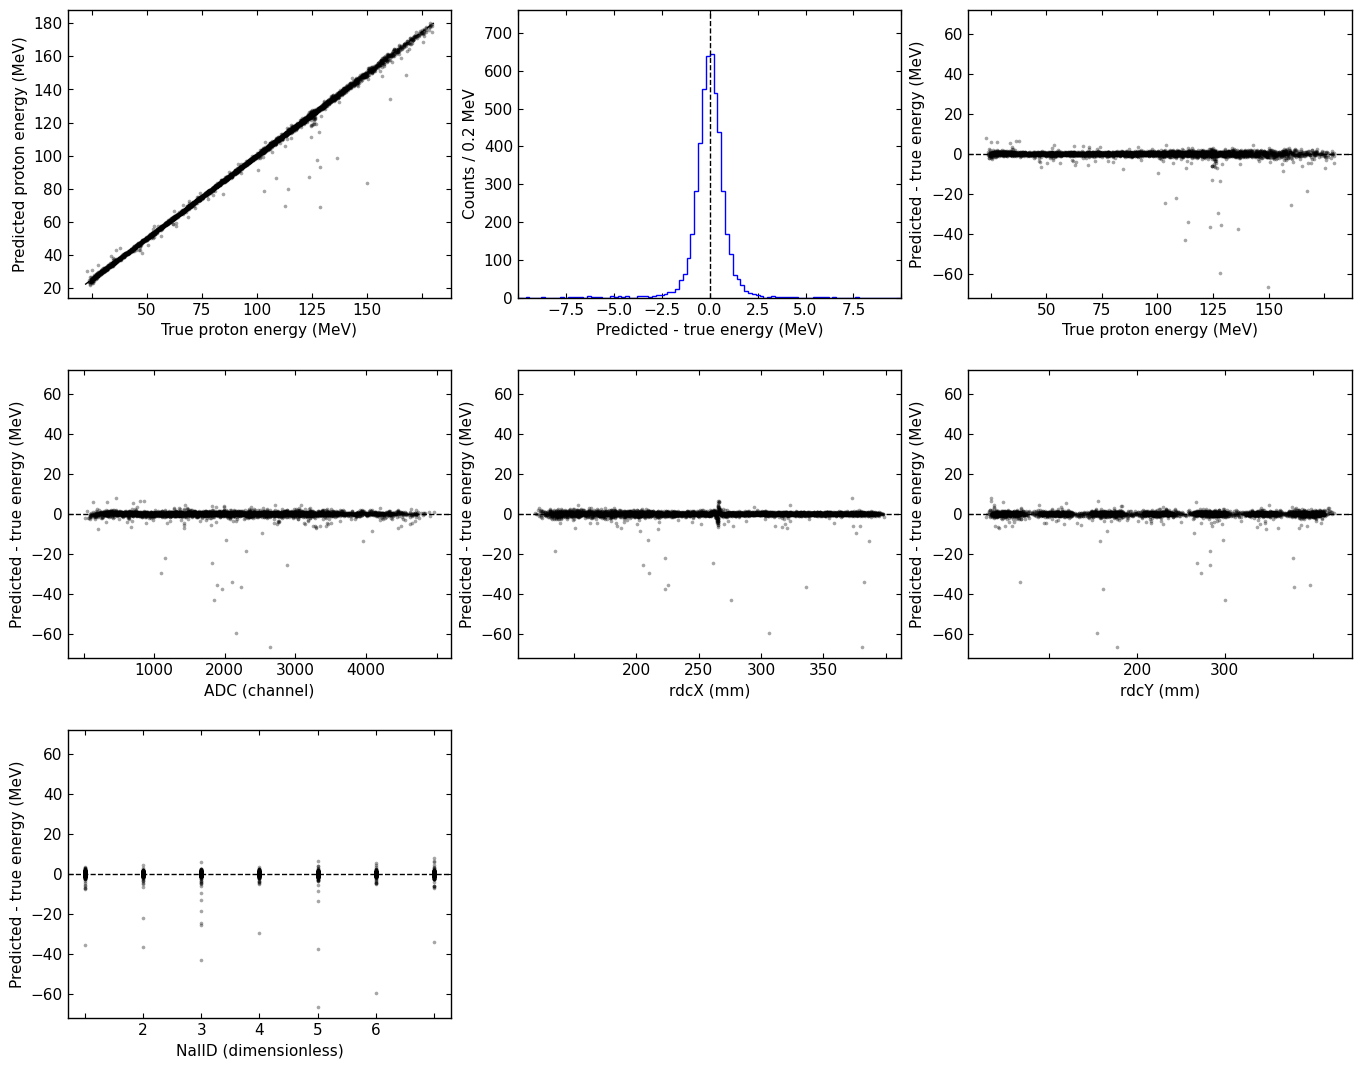

Right internal test: residual histogram below range=22, above range=0; metrics use all 4830 events


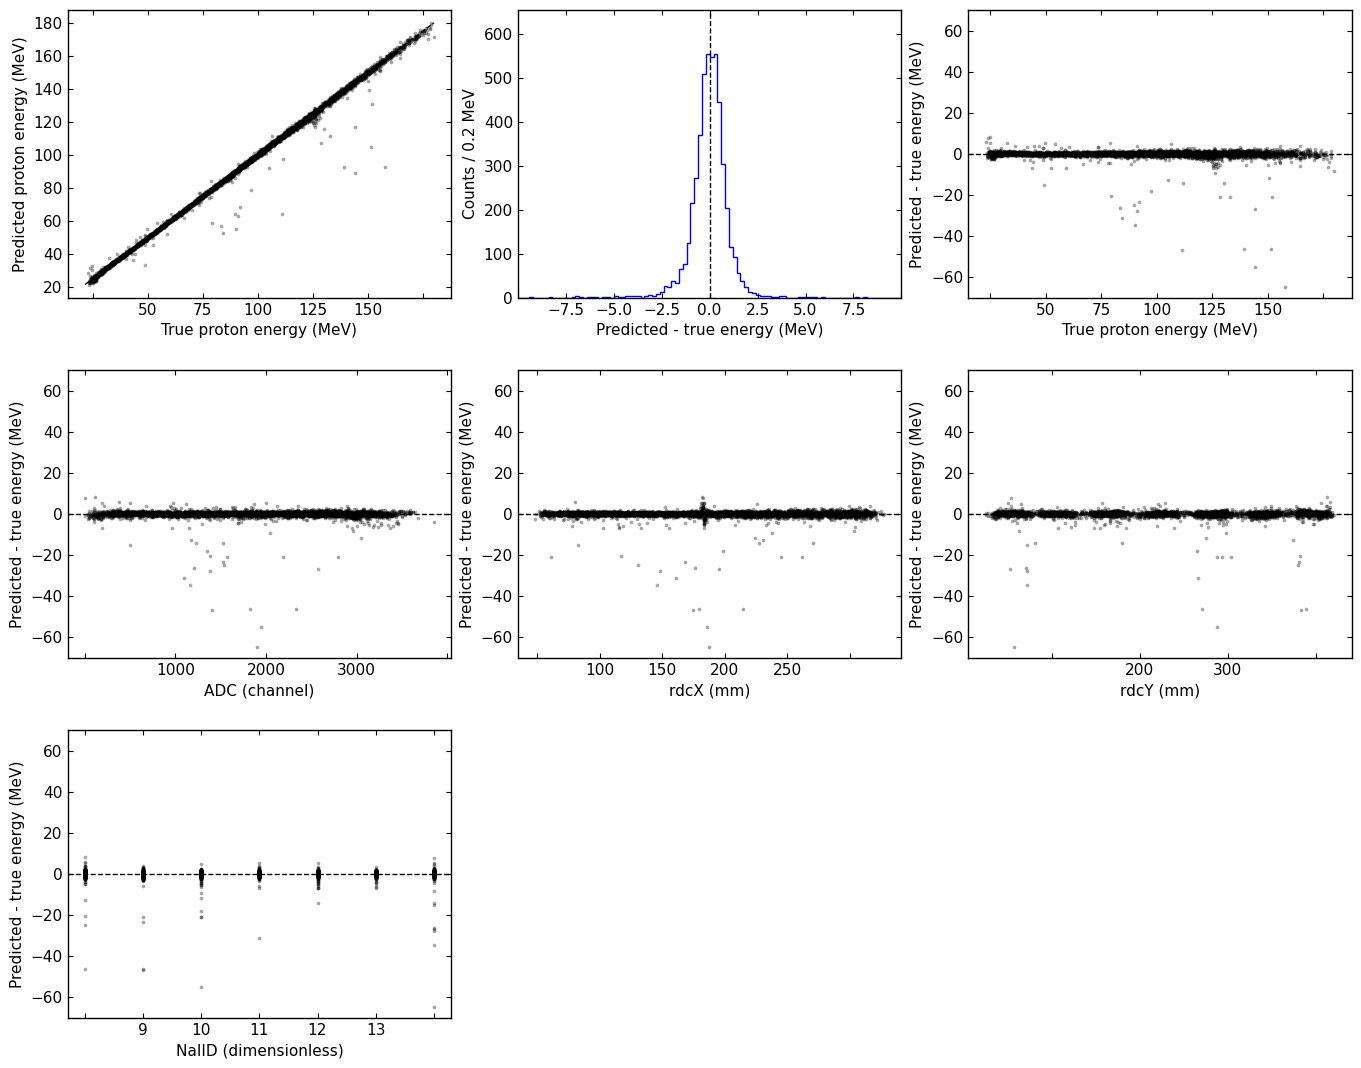


Left Train（完整评估样本数：19204）
平均绝对误差 (Mean Absolute Error, MAE):          0.630338 MeV
平均偏差 (Mean Bias, Bias):                      -0.101245 MeV
均方根误差 (Root Mean Square Error, RMSE):        1.909067 MeV
截尾均方根 (Truncated RMS, RMS_68):               0.310317 MeV
中心68%半宽 (Central 68% Half Width, W_68):       0.591731 MeV

Left Test（完整评估样本数：4802）
平均绝对误差 (Mean Absolute Error, MAE):          0.666126 MeV
平均偏差 (Mean Bias, Bias):                      -0.125218 MeV
均方根误差 (Root Mean Square Error, RMSE):        2.153872 MeV
截尾均方根 (Truncated RMS, RMS_68):               0.322793 MeV
中心68%半宽 (Central 68% Half Width, W_68):       0.612782 MeV

Right Train（完整评估样本数：19319）
平均绝对误差 (Mean Absolute Error, MAE):          0.724624 MeV
平均偏差 (Mean Bias, Bias):                      -0.122804 MeV
均方根误差 (Root Mean Square Error, RMSE):        2.012735 MeV
截尾均方根 (Truncated RMS, RMS_68):               0.365188 MeV
中心68%半宽 (Central 68% Half Width, W_68):       0.694444 MeV

Right Test（完整评估样本数：4830）
平均绝对误差 (Mean Absolute

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [7]:
# 功能：评估左右臂最终模型，导出逐事件测试 CSV、统计 JSON 和诊断图，再打印 Train/Test 五项误差。
# 方法：反归一化到 MeV；残差为预测减真值，RMS_68 使用 Q16–Q84 区间；Unicode 显示列宽用于冒号后的数值对齐。
# 注意事项：完整有效样本参与统计，不按绘图范围筛选；Train 评估覆盖完整训练划分，测试集不参与训练。

def regression_metrics(truth, prediction):
    truth = np.asarray(truth, dtype=np.float64).reshape(-1)
    prediction = np.asarray(prediction, dtype=np.float64).reshape(-1)
    if truth.shape != prediction.shape:
        raise ValueError("真值与预测的事件数不一致。")
    if not np.isfinite(truth).all() or not np.isfinite(prediction).all():
        raise ValueError("真值或预测包含 NaN/Inf，不能静默删除后统计。")
    residual = prediction - truth
    if len(residual) == 0:
        raise ValueError("没有可用于计算误差的有效真值。")
    mse = float(np.mean(residual**2))
    total = float(np.sum((truth - truth.mean())**2))
    q16, q50, q84 = np.quantile(residual, [0.16, 0.50, 0.84])
    core = residual[(residual >= q16) & (residual <= q84)]
    if core.size == 0:
        raise ValueError("Q16–Q84 区间内没有事件，无法计算 RMS_68。")
    return {
        "n": int(len(residual)), "mse_MeV2": mse,
        "rmse_MeV": float(np.sqrt(mse)), "mae_MeV": float(np.mean(np.abs(residual))),
        "r2": float(1.0 - np.sum(residual**2) / total) if total > 0.0 else None,
        "bias_MeV": float(residual.mean()),
        "residual_std_MeV": float(residual.std(ddof=1)) if len(residual) > 1 else 0.0,
        "residual_q16_MeV": float(q16), "residual_median_MeV": float(q50),
        "residual_q84_MeV": float(q84), "central68_half_width_MeV": float((q84 - q16) / 2.0),
        "truncated_rms68_MeV": float(np.sqrt(np.mean(core**2))),
    }

def print_regression_metrics(arm, subset, metrics):
    """保留左侧标签的自然间距，只在冒号后补空格，使五项数值小数点对齐。"""
    import unicodedata

    rows = [
        ("平均绝对误差 (Mean Absolute Error, MAE):", metrics["mae_MeV"]),
        ("平均偏差 (Mean Bias, Bias):", metrics["bias_MeV"]),
        ("均方根误差 (Root Mean Square Error, RMSE):", metrics["rmse_MeV"]),
        ("截尾均方根 (Truncated RMS, RMS_68):", metrics["truncated_rms68_MeV"]),
        ("中心68%半宽 (Central 68% Half Width, W_68):", metrics["central68_half_width_MeV"]),
    ]

    def display_width(text):
        return sum(0 if unicodedata.combining(char) else
                   2 if unicodedata.east_asian_width(char) in ("W", "F") else 1
                   for char in text)

    label_width = max(display_width(label) for label, _ in rows)
    values = [f"{value:.6f}" for _, value in rows]
    value_width = max(14, max(len(value) for value in values))
    print(f"\n{arm} {subset}（完整评估样本数：{metrics['n']}）", flush=True)
    for (label, _), value in zip(rows, values):
        padding = label_width - display_width(label) + 1 + value_width - len(value)
        print(f"{label}{' ' * padding}{value} MeV", flush=True)


def plot_diagnostics(arm, X, truth, prediction, path, sample_label):
    """所有宽度均为样本统计量，不进行高斯拟合。"""
    truth = np.asarray(truth).reshape(-1)
    prediction = np.asarray(prediction).reshape(-1)
    residual = prediction - truth
    metrics = regression_metrics(truth, prediction)
    fig, axes = plt.subplots(3, 3, figsize=(13.5, 10.8), layout="constrained")
    panels = axes.ravel()
    ax = axes[0, 0]
    ax.scatter(truth, prediction, s=7, color="black", alpha=0.35, linewidths=0)
    bounds = [min(truth.min(), prediction.min()), max(truth.max(), prediction.max())]
    ax.plot(bounds, bounds, color="black", linestyle="--", linewidth=1)
    ax.set(xlabel="True proton energy (MeV)", ylabel="Predicted proton energy (MeV)")
    ax = axes[0, 1]
    # 固定 100 个箱；只改变显示，不用这个窗口筛选误差指标。
    bin_count = int(round((RESIDUAL_HIST_MAX_MEV - RESIDUAL_HIST_MIN_MEV) / RESIDUAL_HIST_BIN_WIDTH_MEV))
    histogram_edges = np.linspace(RESIDUAL_HIST_MIN_MEV, RESIDUAL_HIST_MAX_MEV, bin_count + 1)
    counts, edges, _ = ax.hist(residual, bins=histogram_edges, histtype="step", color="blue", linewidth=1)
    ax.set_xlim(RESIDUAL_HIST_MIN_MEV, RESIDUAL_HIST_MAX_MEV)
    print(f"{arm} {sample_label}: residual histogram below range={(residual < RESIDUAL_HIST_MIN_MEV).sum()}, "
          f"above range={(residual > RESIDUAL_HIST_MAX_MEV).sum()}; metrics use all {len(residual)} events")
    ax.set_ylim(0.0, max(1.0, 1.18 * counts.max()))
    ax.set(xlabel="Predicted - true energy (MeV)", ylabel=f"Counts / {edges[1] - edges[0]:.3g} MeV")
    ax.axvline(0.0, color="black", linestyle="--", linewidth=1)
    xs = [truth, *X.T]
    labels = ["True proton energy (MeV)", "ADC (channel)", "rdcX (mm)", "rdcY (mm)", "NaIID (dimensionless)"]
    residual_limit = max(1e-6, 1.08 * np.max(np.abs(residual)))
    for ax, values, label in zip(panels[2:7], xs, labels):
        ax.scatter(values, residual, s=7, color="black", alpha=0.35, linewidths=0)
        ax.axhline(0.0, color="black", linestyle="--", linewidth=1)
        ax.set(xlabel=label, ylabel="Predicted - true energy (MeV)")
        ax.set_ylim(-residual_limit, residual_limit)
    for ax in panels[7:]:
        fig.delaxes(ax)
    finish_figure(fig, panels[:7], path)

all_metrics, test_results = {}, {}
for arm in ("Left", "Right"):
    model, split = models[arm], splits[arm]
    all_metrics[arm] = {}
    model.eval()
    for subset in ("train", "test"):
        with torch.no_grad():
            prediction_n = model(split[f"X_{subset}_t"]).cpu().numpy()
        prediction = prediction_n * split["y_std"] + split["y_mean"]
        truth = split[f"y_{subset}"]
        metrics = regression_metrics(truth, prediction)
        all_metrics[arm][subset] = metrics
        if subset == "test":
            source_rows = datasets[arm]["source_rows"][split["test_idx"]]
            energy_nai = datasets[arm]["energy_nai"][split["test_idx"]]
            result = np.column_stack((source_rows, split["X_test"], energy_nai, truth, prediction, prediction - truth))
            np.savetxt(OUTPUT_DIR / f"Test_{arm}.csv", result, delimiter=",",
                       header="SourceEntry,ADC,rdcX_mm,rdcY_mm,NaIID,ENaI_MeV,ETrue_MeV,EPred_MeV,Residual_MeV",
                       comments="", fmt=["%d"] + ["%.17g"] * 8)
            test_results[arm] = {"X": split["X_test"], "truth": truth, "prediction": prediction}
(OUTPUT_DIR / "metrics.json").write_text(json.dumps(all_metrics, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")

for arm, result in test_results.items():
    plot_diagnostics(arm, result["X"], result["truth"], result["prediction"],
                     OUTPUT_DIR / f"Diag_{arm}.pdf", "internal test")
# 左右臂诊断图全部输出后，集中打印完整 Train/Test 的五项指标。
for arm in ("Left", "Right"):
    for subset in ("Train", "Test"):
        print_regression_metrics(arm, subset, all_metrics[arm][subset.lower()])
print("\n零偏差理想高斯分布：标准差 = σ，RMSE = σ，RMS_68 ≈ 0.54σ，W_68 ≈ 0.994σ。", flush=True)
print("以上关系仅适用于相应高斯假设；不能仅凭 RMS_68/W_68 接近 0.54 判定残差服从高斯分布。", flush=True)
print("所有训练产物：", OUTPUT_DIR)

display(Math(r"r=\hat E-E,\quad \mathrm{MAE}=\langle|r|\rangle,\quad \mathrm{Bias}=\langle r\rangle,\quad \mathrm{RMSE}=\sqrt{\langle r^2\rangle}"))
display(Math(r"\mathrm{RMS}_{68}=\sqrt{\langle r^2\rangle_{Q_{16}\le r\le Q_{84}}},\quad W_{68}=\frac{Q_{84}-Q_{16}}{2}"))


## 8. 保存训练得到的模型及 ADC 定义
保存最后一轮的完整 nn.Sequential 模型、训练归一化、特征顺序与单位、训练/测试行号、
源文件 SHA256、标定原文及 SHA256、14 棒 A/B/C、编号映射、连续 ADC 定义与训练历史。
输出目录在本文件夹内，模型名 `EspriADC_Left.pt`、`EspriADC_Right.pt`。


In [8]:
# 从实际模型提取层宽，网络只在“张量与 MLP”单元格定义。
linear_layers = [layer for layer in models["Left"] if isinstance(layer, nn.Linear)]
layer_sizes = [linear_layers[0].in_features] + [layer.out_features for layer in linear_layers]
configuration = {
    "feature_names": FEATURE_NAMES, "feature_units": FEATURE_UNITS, "target_name": TARGET_NAME,
    "target_definition": "Proton kinetic energy at emission vertex (MeV)",
    "layer_sizes": layer_sizes, "activation": "Tanh", "dtype": "float64", "device": "cpu",
    "adc_formula": "Q=(ENaI-C)/(A-B*(ENaI-C))",
    "adc_quantized": False, "adc_added_noise": False,
    "calibration_path": str(CALIB_PATH), "calibration_sha256": calib_sha256,
    "calibration_columns": ["side", "bar", "A", "B", "C"],
    "calibration_table": calib_table.tolist(),
    "calibration_text": calib_raw.decode("utf-8"), "arm_calibration_mapping": ARM_CALIB,
    "epochs": epoch_count, "batch_size": BATCH_SIZE, "learning_rate": LEARNING_RATE,
    "minimum_learning_rate": MINIMUM_LEARNING_RATE, "cosine_epochs": COSINE_EPOCHS,
    "scheduler": "CosineAnnealingLR", "optimizer": "Adam", "loss": "SmoothL1Loss on standardized ETrue", "smooth_l1_beta": SMOOTH_L1_BETA,
    "train_fraction": TRAIN_FRACTION, "arm_seeds": ARM_SEEDS, "weight_decay": WEIGHT_DECAY,
    "checkpoint_rule": "final_epoch", "torch_version": str(torch.__version__),
}
for arm in ("Left", "Right"):
    split, data = splits[arm], datasets[arm]
    saved = {
        "model": models[arm].cpu().eval(), "arm": arm,
        "feature_names": FEATURE_NAMES.copy(), "feature_units": FEATURE_UNITS.copy(),
        "target_name": TARGET_NAME, "target_unit": "MeV",
        "target_definition": configuration["target_definition"],
        "x_mean": split["x_mean"], "x_std": split["x_std"],
        "y_mean": split["y_mean"], "y_std": split["y_std"],
        "train_feature_min": split["X_train"].min(axis=0),
        "train_feature_max": split["X_train"].max(axis=0),
        "source_rows_train": data["source_rows"][split["train_idx"]],
        "source_rows_test": data["source_rows"][split["test_idx"]],
        "input_path": str(data["input_path"]), "input_sha256": data["input_sha256"],
        "tree_name": TREE_NAME, "original_entries": data["original_entries"],
        "rejected_entries": data["rejected_entries"], "epoch": epoch_count,
        "configuration": configuration, "history": histories[arm],
    }
    checkpoint_path = OUTPUT_DIR / f"EspriADC_{arm}.pt"
    torch.save(saved, checkpoint_path)
    np.savez(OUTPUT_DIR / f"History_{arm}.npz", **histories[arm])
    print("Saved:", checkpoint_path)
(OUTPUT_DIR / "config.json").write_text(json.dumps(configuration, ensure_ascii=False, indent=2), encoding="utf-8")
print("预测配置 MODEL_DIR =", repr(str(OUTPUT_DIR)))


Saved: /Users/yemingxin/ROOT_Exercise/MachineLearning/EspriEnergy/ADCToProtonEnergy/ADC_output/EspriADC_Left.pt
Saved: /Users/yemingxin/ROOT_Exercise/MachineLearning/EspriEnergy/ADCToProtonEnergy/ADC_output/EspriADC_Right.pt
预测配置 MODEL_DIR = '/Users/yemingxin/ROOT_Exercise/MachineLearning/EspriEnergy/ADCToProtonEnergy/ADC_output'


## 9. 独立加载与预测（可选，不训练）
下方单元格只定义加载/预测函数。将本次输出目录下可信的 `EspriADC_Left.pt` 或 `EspriADC_Right.pt`
传给函数；输入必须为对应臂的 `[ADC, rdcX, rdcY, NaIID]`、二维 float64 数组，不能把 ENaI 当 ADC。
ADC 必须具有模型保存的连续 Q 定义。预测只复用已保存的归一化，不重新拟合。
若从模拟 ENaI 生成预测输入，须使用 checkpoint 中的标定与编号映射，可用上方 `energy_to_adc` 回代检查；
不能无检查换用更新后的外部标定表。独立评估时仍应保持事件和真值的对应关系。
使用已有预处理数据即可；新数据训练前建议先通过 `PreProcess.C` 清洗数据。


In [9]:
# 功能：从可信 checkpoint 独立加载完整模型，对对应臂的四输入进行预测；不训练、不写文件。
# 方法：复用保存的输入顺序和训练集归一化，在 CPU float64 的 eval/no_grad 下推理。
# 注意事项：ADC 必须遵循 checkpoint 的连续 Q 定义；完整模型反序列化仅用于可信文件。
def predict_adc(checkpoint_path, X):
    import numpy as np
    import torch
    saved = torch.load(checkpoint_path, map_location="cpu", weights_only=False)
    if saved["feature_names"] != ["ADC", "rdcX", "rdcY", "NaIID"]:
        raise ValueError("checkpoint 输入定义不匹配。")
    X = np.asarray(X, dtype=np.float64)
    if X.ndim != 2 or X.shape[1] != 4 or len(X) == 0 or not np.isfinite(X).all():
        raise ValueError("输入必须为非空、有限的 N×4 数组。")
    rule = saved["configuration"]["arm_calibration_mapping"][saved["arm"]]
    ids = X[:, 3]
    if (np.any(X[:, 0] < 0) or np.any(X[:, 1:3] == -999.0)
            or np.any(ids != np.floor(ids)) or np.any(ids < rule["id_min"])
            or np.any(ids > rule["id_min"] + 6)):
        raise ValueError("ADC、坐标或 NaIID 无效/与模型臂不匹配。")
    model = saved["model"].to(device="cpu", dtype=torch.float64).eval()
    x_mean, x_std = (np.asarray(saved[key], dtype=np.float64) for key in ("x_mean", "x_std"))
    tensor = torch.from_numpy(np.ascontiguousarray((X - x_mean) / x_std))
    with torch.no_grad():
        prediction = model(tensor).cpu().numpy()
    prediction = prediction * np.asarray(saved["y_std"]) + np.asarray(saved["y_mean"])
    if not np.isfinite(prediction).all():
        raise ValueError("预测包含 NaN/Inf。")
    return prediction
